# Project01 Tri thức và truy xuất đồ thị

Mục tiêu: theo dõi đường đi từ ghi chú có nguồn tới bằng chứng và câu trả lời. Đây là RAG theo kiểu trích xuất, không có LLM sinh tự do. Đồ thị local là JSON với cạnh tường minh; file Cypher chỉ là bản xuất tùy chọn.

In [1]:
# Chạy được khi kernel bắt đầu ở PROJECT_01 hoặc notebooks.
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "diabetes_agent").exists() else Path.cwd().parent
assert (ROOT / "diabetes_agent").exists(), "Mở notebook từ thư mục PROJECT_01"
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from diabetes_agent.config import ARTIFACTS, DATA, FEATURES
print("Python:", sys.version.split()[0], "| Project:", ROOT.name)

Python: 3.11.9 | Project: PROJECT_01


## 1 Kiểm tra cấu trúc kho tri thức
12 ghi chú tiếng Việt biên soạn ngắn từ 7 trang NIDDK/CDC, có URL, ngày kiểm tra và ID. Đây không phải 12 tài liệu gốc đầy đủ hoặc kho hướng dẫn lâm sàng.

In [2]:
from diabetes_agent.knowledge import KnowledgeBase
kb = KnowledgeBase()
display(pd.DataFrame(kb.docs)[["id", "title", "concepts", "source_title", "checked_at"]])
print("Số khái niệm:", len(kb.graph["concepts"]))
display(pd.DataFrame(kb.graph["relations"]))

,id,title,concepts,source_title,checked_at
0,D01,Tiểu đường và insulin,[diabetes],NIDDK What Is Diabetes,2026-11-05
1,D02,Các loại tiểu đường,[types],NIDDK What Is Diabetes,2026-11-05
2,D03,Xét nghiệm và xác nhận,[tests],NIDDK Diabetes Tests and Diagnosis,2026-11-05
3,D04,Glucose lúc đói,[fasting],NIDDK Diabetes Tests and Diagnosis,2026-11-05
4,D05,Đường huyết thấp,[hypoglycemia],CDC Treatment of Low Blood Sugar,2026-11-05
5,D06,HbA1c phản ánh thời gian dài,[a1c],NIDDK The A1C Test and Diabetes,2026-11-05
6,D07,Giới hạn của HbA1c,[a1c_limits],NIDDK The A1C Test and Diabetes,2026-11-05
7,D08,Nhật ký theo dõi,[journal],NIDDK Managing Diabetes,2026-11-05
8,D09,Mục tiêu và thuốc,[care],NIDDK Managing Diabetes,2026-11-05
9,D10,Ăn uống và khẩu phần,[nutrition],CDC Diabetes Meal Planning,2026-11-05


Số khái niệm: 12


,source,target,type
0,diabetes,tests,assessed_by
1,tests,fasting,includes
2,tests,a1c,includes
3,a1c,a1c_limits,has_limitation
4,diabetes,care,managed_with
5,care,journal,uses
6,nutrition,carbs,includes
7,care,activity,includes


## 2 Thuật toán truy xuất
Chuẩn hóa chữ thường, bỏ dấu; TF-IDF unigram/bigram và cosine similarity. Từ khóa alias xác định khái niệm, mở rộng cạnh có hướng một bước; ghi chú liên quan được cộng 0.12. Cần khớp alias hoặc ít nhất hai token ở tiêu đề/từ khóa để hạn chế kết quả do từ chức năng. Điểm cosine tối thiểu 0.10 khi không khớp trực tiếp. Các hằng số là lựa chọn cài đặt, chưa tối ưu trên dữ liệu độc lập.

In [3]:
query = "HbA1c và thiếu máu"
hits = kb.retrieve(query)
display(pd.DataFrame(hits)[["id", "title", "lexical_score", "score", "matched_concepts"]])
print(kb.answer(query)["text"])
for item in hits:
    print(item["id"], item["source_url"])

,id,title,lexical_score,score,matched_concepts
0,D07,Giới hạn của HbA1c,0.313424,0.433424,[a1c_limits]
1,D06,HbA1c phản ánh thời gian dài,0.134940,0.254940,[a1c]


Một số tình trạng ảnh hưởng hồng cầu hoặc hemoglobin có thể làm HbA1c kém tin cậy. Khi kết quả không phù hợp, cần trao đổi với nhân viên y tế. [D07]

HbA1c phản ánh đường huyết trung bình khoảng ba tháng, khác số đo tức thời. Cần đọc kết quả cùng bối cảnh và hướng dẫn chuyên môn. [D06]
D07 https://www.niddk.nih.gov/health-information/diagnostic-tests/a1c-test
D06 https://www.niddk.nih.gov/health-information/diagnostic-tests/a1c-test


## 3 Từ chối khi thiếu bằng chứng
Bộ lọc lexical không bảo đảm hiểu ngữ nghĩa; câu hỏi không có căn cứ phù hợp cần trả trạng thái riêng.

In [4]:
unknown = kb.answer("Vệ tinh Sao Hỏa")
print(unknown)
assert unknown["status"] == "insufficient_evidence"
print([d["id"] for d in kb.retrieve("hba1c ba thang")])

{'status': 'insufficient_evidence', 'evidence': [], 'text': 'Kho tri thức chưa có căn cứ phù hợp. Hãy hỏi về xét nghiệm, theo dõi hoặc lối sống.'}
['D06']


## 4 Đối chiếu truy xuất có và không có đồ thị
24 câu do tác giả soạn, mỗi ghi chú hai câu, một ID mục tiêu mỗi câu. Hit@k đo tìm đúng ID trong k kết quả. MRR là trung bình nghịch đảo thứ hạng. Bộ câu nhỏ và dùng cùng từ vựng kho tri thức nên không đại diện câu hỏi người bệnh ngoài thực tế.

In [5]:
import json
cases = json.loads((DATA / "retrieval_cases.json").read_text(encoding="utf-8"))
rows = []
for use_graph in (False, True):
    for case in cases:
        ids = [d["id"] for d in kb.retrieve(case["query"], graph=use_graph)]
        rank = ids.index(case["expected_id"]) + 1 if case["expected_id"] in ids else None
        rows.append({"graph": use_graph, "query": case["query"], "hit1": rank == 1,
                     "hit3": rank is not None, "rr": 1/rank if rank else 0})
results = pd.DataFrame(rows)
display(results.groupby("graph")[["hit1", "hit3", "rr"]].mean())
display(results)

,hit1,hit3,rr
graph,,,
False,1.0,1.0,1.0
True,1.0,1.0,1.0


,graph,query,hit1,hit3,rr
0,False,Tiểu đường là gì và insulin có vai trò gì?,True,True,1.0
1,False,Tìm hiểu khái niệm đái tháo đường,True,True,1.0
2,False,Phân biệt type 1 type 2 và thai kỳ,True,True,1.0
3,False,Có những loại tiểu đường nào?,True,True,1.0
4,False,Cần xét nghiệm để xác nhận chẩn đoán không?,True,True,1.0
5,False,Điểm mô hình thay được xét nghiệm không?,True,True,1.0
6,False,Nhịn ăn bao lâu trước xét nghiệm lúc đói?,True,True,1.0
7,False,Glucose lúc đói khác số đo bất kỳ thế nào?,True,True,1.0
8,False,Hạ đường huyết là gì?,True,True,1.0
9,False,Đường huyết thấp dưới 70 mg có đáng lưu ý?,True,True,1.0


## 5 Xem phần mã chịu trách nhiệm truy xuất
Sử dụng chính class của demo. Council sẽ kiểm tra ID bằng chứng, nhưng ID hợp lệ không chứng minh đoạn trích đã trả lời đúng ý người hỏi.

    def retrieve(self, query, k=3, graph=True):
        q = normalize(query)
        if not q.strip():
            return []
        lexical = cosine_similarity(self.vectorizer.transform([query]), self.matrix).ravel()
        concepts = {n["id"] for n in self.graph["concepts"]
                    if any(re.search(r"(?<!\w)" + re.escape(normalize(a)) + r"(?!\w)", q)
                           for a in n["aliases"])}
        expanded = set(concepts)
        if graph:
            for edge in self.graph["relations"]:
                if edge["source"] in concepts:
                    expanded.add(edge["target"])
        results = []
        query_terms = set(re.findall(r"\w+", q)) - {"la", "gi", "va", "co", "khong", "toi", "can", "the", "nao", "cua", "cho"}
        for i, doc in enumerate(self.docs):
            matched = set(doc["concepts"]) & expanded
            bonus = .12 if graph and matched else 0.
            # Do not let graph proximity create evidence for an unrelated query.
     

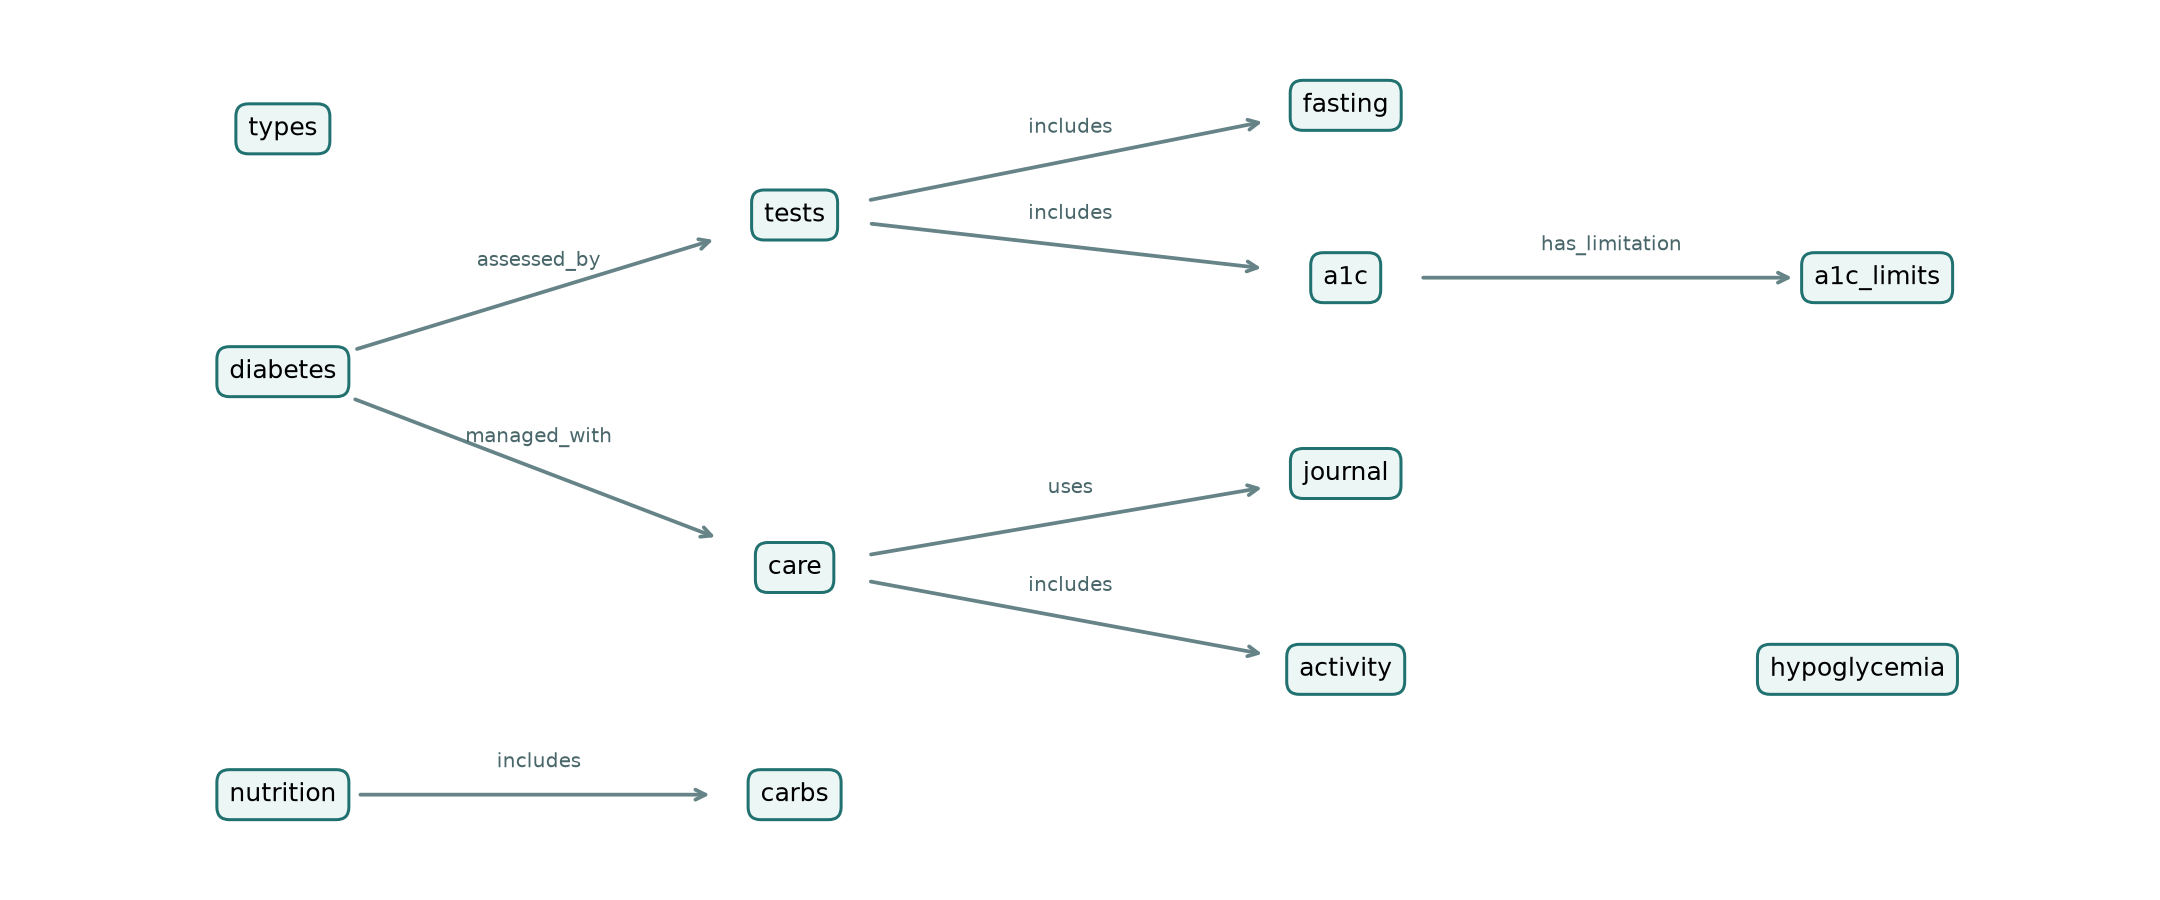

In [6]:
import inspect
print(inspect.getsource(KnowledgeBase.retrieve))
if (ARTIFACTS / "figures/knowledge_graph.png").exists():
    display(Image(filename=str(ARTIFACTS / "figures/knowledge_graph.png")))